# Consumer sum resistance (VSW)
Analyse the resistance in grids. The VSW is a parameter of a grid that incorporates the power demand, resistance of the cable and the cable length. The VSW is in indicator of how much the voltage can drop in a network.

> **Note:** This notebook needs a classification data set of many postcode areas (sample set, generated and analysed grids, clustering parameters; see the classification documentation and `pylovo-classify`). The stored outputs come from an earlier classification run with an older pylovo version; they were kept when the imports were updated and were not re-created.

In [ ]:
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

from pylovo.classification.database_communication.database_communication import DatabaseCommunication
from pylovo.plotting.generation.networks import (
    get_network_info_for_plotting,
    plot_grid_on_map,
    plot_with_generic_coordinates,
    read_net_with_grid_generator,
)

warnings.filterwarnings('ignore')

dc = DatabaseCommunication()
df_parameters_of_grids = dc.municipal_register_with_clustering_parameters_for_classification_version()

Database connection is constructed. 


## max VSW of a branch
Of special interest is the max vsw of a single branch. That is the branch where the maximum voltage drop in the grid is to be expected.
First we look at the distribution and the statistics.

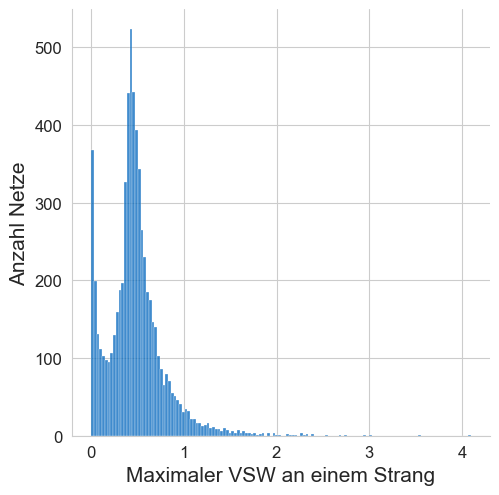

In [15]:
sns.displot(data=df_parameters_of_grids['max_vsw_of_a_branch'])
plt.xlabel('Largest VSW of a feeder', fontsize=15)
plt.ylabel('Grids', fontsize=15)
plt.tick_params(axis='both', which='major', labelsize=12)
# plt.savefig('vsw_distribution.png', dpi=600)

In [3]:
df_parameters_of_grids['max_vsw_of_a_branch'].describe()

count    6444.000000
mean        0.475810
std         0.312665
min         0.000118
25%         0.315153
50%         0.448347
75%         0.591311
max         4.090552
Name: max_vsw_of_a_branch, dtype: float64

Next we look at the grids with the heighest VSW. If the voltage drop is too large it might cause a failure in the grid.

In [4]:
sorted_df = df_parameters_of_grids.sort_values('max_vsw_of_a_branch', ascending=False)
sorted_df = sorted_df[
    ['plz', 'kcid', 'bcid', 'max_household_equ_of_a_branch', 'max_trafo_dis', 'max_vsw_of_a_branch']]
sorted_df = sorted_df.head(100)
sorted_df

,plz,kcid,bcid,max_household_equ_of_a_branch,max_trafo_dis,max_vsw_of_a_branch
5666,83458,5,2,34.000000,1.490014,4.090552
6181,96250,2,1,60.000000,2.091344,3.539642
2853,82327,2,2,77.000000,1.458104,3.003696
3000,85092,1,1,70.000000,2.396983,2.962733
4444,84524,2,6,53.000000,1.401875,2.742644
175,80937,1,-5,154.000000,0.290778,2.687216
562,81249,1,0,40.000000,0.245606,2.532564
6128,94351,1,1,48.000000,1.925057,2.394202
5650,83458,9,1,2.000000,1.159990,2.372327
4843,86911,2,4,59.000000,1.765193,2.337327


<Axes: xlabel='max_trafo_dis', ylabel='max_vsw_of_a_branch'>

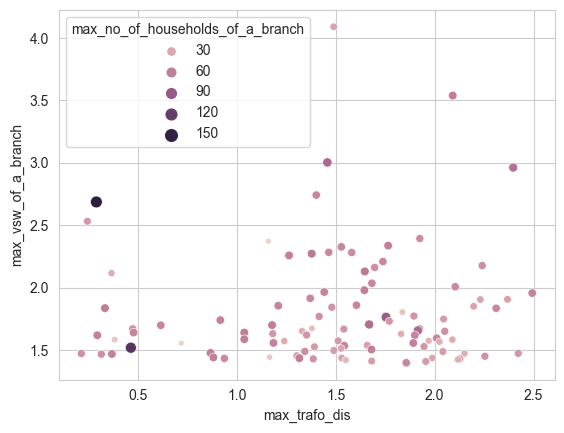

In [5]:
sns.scatterplot(data=sorted_df, x='max_trafo_dis', y='max_vsw_of_a_branch', hue='max_household_equ_of_a_branch',
                size='max_household_equ_of_a_branch')

linear regression

<Axes: xlabel='max_trafo_dis', ylabel='max_vsw_of_a_branch'>

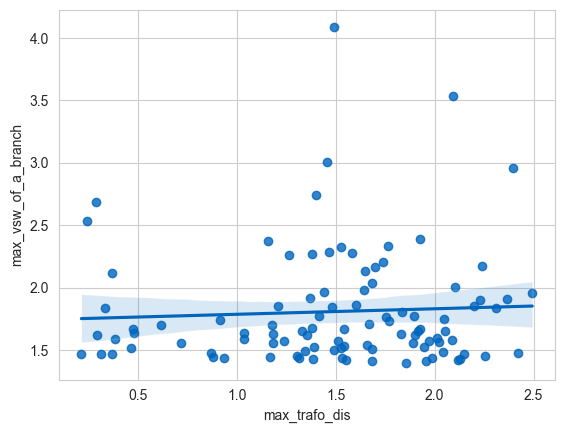

In [6]:
sns.regplot(data=sorted_df, x='max_trafo_dis', y='max_vsw_of_a_branch')

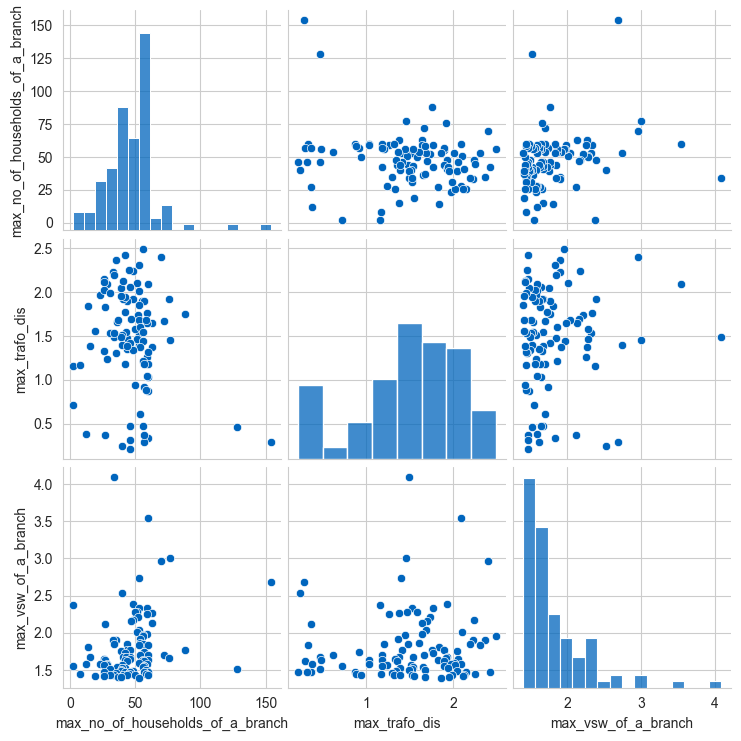

In [7]:

sns.pairplot(sorted_df[
                 ['max_household_equ_of_a_branch', 'max_trafo_dis', 'max_vsw_of_a_branch']])

In [8]:
#df_vsw_branch_max = df_parameters_of_grids.loc[df_parameters_of_grids['max_vsw_of_a_branch'].idxmax()]
df_vsw_branch_max = sorted_df.iloc[0]
print(df_vsw_branch_max)

plz                                    83458
kcid                                       5
bcid                                       2
max_household_equ_of_a_branch        34.0
max_trafo_dis                       1.490014
max_vsw_of_a_branch                 4.090552
Name: 5666, dtype: object


In [9]:
plz, kcid, bcid = get_network_info_for_plotting(df_vsw_branch_max)

In [10]:
plot_with_generic_coordinates(plz=plz, kcid=kcid, bcid=bcid)

PgReaderWriter is constructed. 
Version: 1 (already exists)
Parameter tables are inserted
PgReaderWriter closed.
PgReaderWriter closed.


In [11]:
plot_grid_on_map(plz=plz, kcid=kcid, bcid=bcid)

PgReaderWriter is constructed. 
Version: 1 (already exists)
Parameter tables are inserted
PgReaderWriter closed.
PgReaderWriter closed.


Test if geo-data are in lat/long cannot be performed using geopy -> eventual plot errors are possible.


In [12]:
net = read_net_with_grid_generator(plz, kcid, bcid)

PgReaderWriter is constructed. 
Version: 1 (already exists)
Parameter tables are inserted
PgReaderWriter closed.
PgReaderWriter closed.


In [13]:
net.load

,name,bus,p_mw,q_mvar,const_z_percent,const_i_percent,sn_mva,scaling,in_service,type,max_p_mw
0,Load 1021 household 1,54,0.0,0.0,0.0,0.0,NaN,1.0,True,wye,0.03
1,Load 1058 household 1,55,0.0,0.0,0.0,0.0,NaN,1.0,True,wye,0.03
2,Load 1061 household 1,56,0.0,0.0,0.0,0.0,NaN,1.0,True,wye,0.03
3,Load 1063 household 1,57,0.0,0.0,0.0,0.0,NaN,1.0,True,wye,0.03
4,Load 1065 household 1,58,0.0,0.0,0.0,0.0,NaN,1.0,True,wye,0.03
5,Load 1067 household 1,59,0.0,0.0,0.0,0.0,NaN,1.0,True,wye,0.03
6,Load 1070 household 1,60,0.0,0.0,0.0,0.0,NaN,1.0,True,wye,0.03
7,Load 1073 household 1,61,0.0,0.0,0.0,0.0,NaN,1.0,True,wye,0.03
8,Load 1326 household 1,62,0.0,0.0,0.0,0.0,NaN,1.0,True,wye,0.03
9,Load 1329 household 1,63,0.0,0.0,0.0,0.0,NaN,1.0,True,wye,0.03


In [14]:
net.bus


,name,vn_kv,type,zone,in_service,min_vm_pu,max_vm_pu
0,LVbus 1,0.4,n,None,True,0.95,1.05
1,MVbus 1,20.0,n,None,True,0.95,1.05
2,Connection Nodebus 1442,0.4,n,None,True,0.95,1.05
3,Connection Nodebus 1074,0.4,n,None,True,0.95,1.05
4,Connection Nodebus 1458,0.4,n,None,True,0.95,1.05
5,Connection Nodebus 2220,0.4,n,None,True,0.95,1.05
6,Connection Nodebus 2065,0.4,n,None,True,0.95,1.05
7,Connection Nodebus 1330,0.4,n,None,True,0.95,1.05
8,Connection Nodebus 1940,0.4,n,None,True,0.95,1.05
9,Connection Nodebus 2024,0.4,n,None,True,0.95,1.05
